<a href="https://colab.research.google.com/github/vasquezEmanuel/statoil-iceberg-classifier-challenge/blob/main/01_exploraci%C3%B3n_de_datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploración de datos — Statoil/C-CORE Iceberg Classifier

Las imágenes provienen de un satélite de radar de apertura sintética (SAR) que observa el mar desde ~680 km de altura. Cada muestra es un recorte de 75×75 píxeles con dos bandas (polarizaciones **HH** y **HV**, en dB) y el ángulo de incidencia del radar (`inc_angle`). La tarea es binaria: **barco (0)** o **iceberg (1)**.

En este notebook se descargan los datos y se estudian sus propiedades: balance de clases, aspecto de las imágenes, estadísticas por clase y, sobre todo, el comportamiento de `inc_angle`, que puede introducir un sesgo si no se trata con cuidado.

## Obtención de los datos

Los datos pertenecen a la competición [Statoil/C-CORE Iceberg Classifier Challenge](https://www.kaggle.com/c/statoil-iceberg-classifier-challenge) y se descargan con la API de Kaggle. Hace falta:

1. Una cuenta de Kaggle y haber aceptado las reglas de la competición (pestaña *Rules* → *I Understand and Accept*). Sin este paso la descarga responde `403 Forbidden`.
2. Un archivo `kaggle.json` con credenciales *legacy*: en Kaggle, *Settings → API → Legacy API Credentials → Create Legacy API Key*.

Al ejecutar la celda se pide subir `kaggle.json`. El archivo se lee, se borra del disco de la sesión y nunca se guarda en el notebook. Solo se descarga `train.json` (1 604 imágenes), el único conjunto con etiquetas.

In [2]:
import os, sys, json, glob, shutil, zipfile, subprocess, importlib.util

COMPETICION = "statoil-iceberg-classifier-challenge"
DATA_DIR = "data"
TRAIN_JSON = os.path.join(DATA_DIR, "train.json")


def _instalar_dependencias():
    faltan = [p for p in ("kaggle", "py7zr") if importlib.util.find_spec(p) is None]
    if faltan:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)


def _cargar_credenciales():
    """Define KAGGLE_USERNAME y KAGGLE_KEY a partir de un kaggle.json (credenciales legacy)."""
    if os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"):
        return
    ruta = os.path.expanduser("~/.kaggle/kaggle.json")
    if os.path.exists(ruta):
        with open(ruta) as f:
            cred = json.load(f)
    else:
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError(
                "No se encontraron credenciales: coloca kaggle.json en ~/.kaggle/ "
                "o define las variables KAGGLE_USERNAME y KAGGLE_KEY."
            )
        print("Selecciona tu archivo kaggle.json")
        subido = files.upload()
        nombre = next((n for n in subido if n.lower().endswith(".json")), None)
        if nombre is None:
            raise RuntimeError("No se subió ningún archivo .json")
        cred = json.loads(subido[nombre])
        try:
            os.remove(nombre)
        except OSError:
            pass
    if "username" not in cred or "key" not in cred:
        raise RuntimeError(
            "El archivo no contiene 'username' y 'key'. Genera una Legacy API Key en "
            "Kaggle (Settings → API → Legacy API Credentials → Create Legacy API Key)."
        )
    os.environ["KAGGLE_USERNAME"] = cred["username"]
    os.environ["KAGGLE_KEY"] = cred["key"]


def _extraer():
    """Descomprime los .zip / .7z de train que haya en data/ y deja train.json en data/train.json."""
    import py7zr
    hay_trabajo = True
    while hay_trabajo:
        hay_trabajo = False
        for ruta in glob.glob(os.path.join(DATA_DIR, "**", "*"), recursive=True):
            if not os.path.isfile(ruta):
                continue
            nombre, destino = os.path.basename(ruta).lower(), os.path.dirname(ruta)
            if nombre.endswith(".zip") and zipfile.is_zipfile(ruta):
                with zipfile.ZipFile(ruta) as z:
                    for miembro in z.namelist():
                        if "train" in os.path.basename(miembro).lower():
                            z.extract(miembro, destino)
                os.remove(ruta)
                hay_trabajo = True
                break
            if nombre.endswith(".7z") and nombre.startswith("train"):
                with py7zr.SevenZipFile(ruta) as z:
                    z.extractall(path=destino)
                os.remove(ruta)
                hay_trabajo = True
                break
    encontrados = glob.glob(os.path.join(DATA_DIR, "**", "train.json"), recursive=True)
    if encontrados and os.path.abspath(encontrados[0]) != os.path.abspath(TRAIN_JSON):
        carpeta = os.path.relpath(encontrados[0], DATA_DIR).split(os.sep)[0]
        shutil.move(encontrados[0], TRAIN_JSON)
        shutil.rmtree(os.path.join(DATA_DIR, carpeta), ignore_errors=True)


def _descargar():
    os.makedirs(DATA_DIR, exist_ok=True)
    salida = ""
    for extra in (["-f", "train.json.7z"], []):  # primero solo train; si falla, el paquete completo
        cmd = [sys.executable, "-m", "kaggle", "competitions", "download",
               "-c", COMPETICION, "-p", DATA_DIR, *extra]
        r = subprocess.run(cmd, capture_output=True, text=True)
        salida = (r.stdout + "\n" + r.stderr).strip()
        _extraer()
        if os.path.exists(TRAIN_JSON):
            return
    raise RuntimeError(
        "No se pudo obtener train.json. Respuesta de Kaggle:\n\n" + salida + "\n\n"
        "Revisa lo siguiente:\n"
        "  1. Aceptaste las reglas en https://www.kaggle.com/c/" + COMPETICION + "/rules (error 403).\n"
        "  2. El kaggle.json es una Legacy API Key vigente; crear una nueva invalida la anterior (error 401).\n"
        "  3. Alternativa manual: descarga train.json.7z desde la pestaña Data de la competición, "
        "súbelo a la carpeta data/ y vuelve a ejecutar esta celda."
    )


if not os.path.exists(TRAIN_JSON):
    _instalar_dependencias()
    _extraer()  # cubre el caso de que el archivo ya esté en data/
if not os.path.exists(TRAIN_JSON):
    _cargar_credenciales()
    _descargar()

print(f"Datos listos: {TRAIN_JSON} ({os.path.getsize(TRAIN_JSON) / 1e6:.0f} MB)")

Datos listos: data/train.json (196 MB)


## Carga y estructura

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
ETIQUETAS = {0: "barco", 1: "iceberg"}
COLORES = {0: "#d95f02", 1: "#1b7fb8"}

df = pd.read_json(TRAIN_JSON)
df["inc_angle"] = pd.to_numeric(df["inc_angle"], errors="coerce")  # 'na' -> NaN

print(f"Imágenes: {len(df)}")
print(f"Columnas: {list(df.columns)}")
print(f"Cada banda tiene {len(df.loc[0, 'band_1'])} valores = 75 x 75 píxeles")
print(f"Peso en memoria del DataFrame: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")
df.drop(columns=["band_1", "band_2"]).head()

Imágenes: 1604
Columnas: ['id', 'band_1', 'band_2', 'inc_angle', 'is_iceberg']
Cada banda tiene 5625 valores = 75 x 75 píxeles
Peso en memoria del DataFrame: 151 MB


,id,inc_angle,is_iceberg
0,dfd5f913,43.9239,0
1,e25388fd,38.1562,0
2,58b2aaa0,45.2859,1
3,4cfc3a18,43.8306,0
4,271f93f4,35.6256,0


## Distribución de las clases

barco   :  851 imágenes (53.1%)
iceberg :  753 imágenes (46.9%)


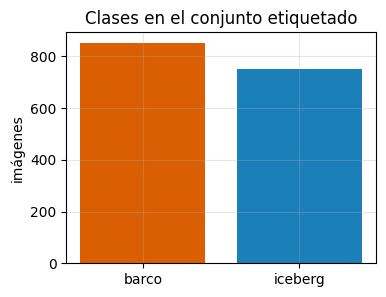

In [4]:
conteo = df["is_iceberg"].value_counts().sort_index()
for c, n in conteo.items():
    print(f"{ETIQUETAS[c]:8s}: {n:4d} imágenes ({n / len(df):.1%})")

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar([ETIQUETAS[c] for c in conteo.index], conteo.values, color=[COLORES[c] for c in conteo.index])
ax.set_ylabel("imágenes"); ax.set_title("Clases en el conjunto etiquetado")
plt.show()

## Aspecto de las imágenes

Se muestran ocho ejemplos de cada clase, con una fila por banda. En las imágenes SAR, un objeto aparece como una mancha brillante sobre un fondo de ruido (*speckle*) del mar.

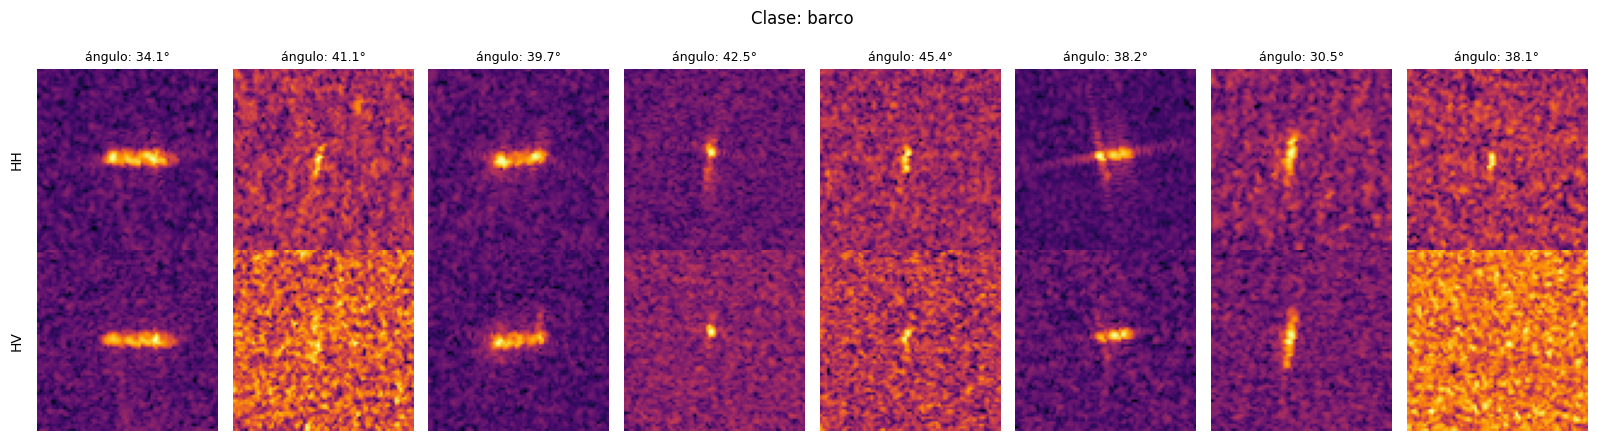

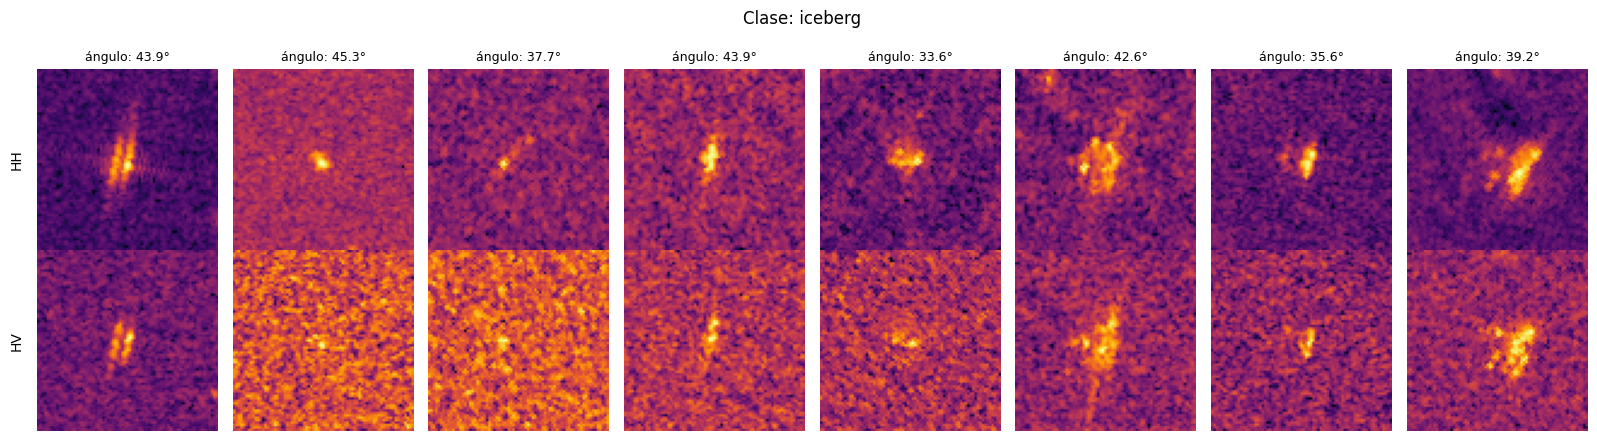

In [5]:
rng = np.random.default_rng(0)
for clase in (0, 1):
    idx = rng.choice(df.index[df["is_iceberg"] == clase], 8, replace=False)
    fig, ejes = plt.subplots(2, 8, figsize=(16, 4.4))
    for j, i in enumerate(idx):
        for fila, banda in enumerate(("band_1", "band_2")):
            img = np.array(df.loc[i, banda]).reshape(75, 75)
            ejes[fila, j].imshow(img, cmap="inferno")
            ejes[fila, j].axis("off")
            if fila == 0:
                ang = df.loc[i, "inc_angle"]
                ejes[fila, j].set_title("ángulo: " + ("n/d" if np.isnan(ang) else f"{ang:.1f}°"), fontsize=9)
    ejes[0, 0].text(-0.15, 0.5, "HH", transform=ejes[0, 0].transAxes, rotation=90, va="center")
    ejes[1, 0].text(-0.15, 0.5, "HV", transform=ejes[1, 0].transAxes, rotation=90, va="center")
    fig.suptitle(f"Clase: {ETIQUETAS[clase]}", y=1.0)
    plt.tight_layout(); plt.show()

## Estadísticas por imagen

Se resumen los 5 625 píxeles de cada banda en tres números (media, desviación y máximo) para ver qué tan separables son las clases con descriptores muy simples.

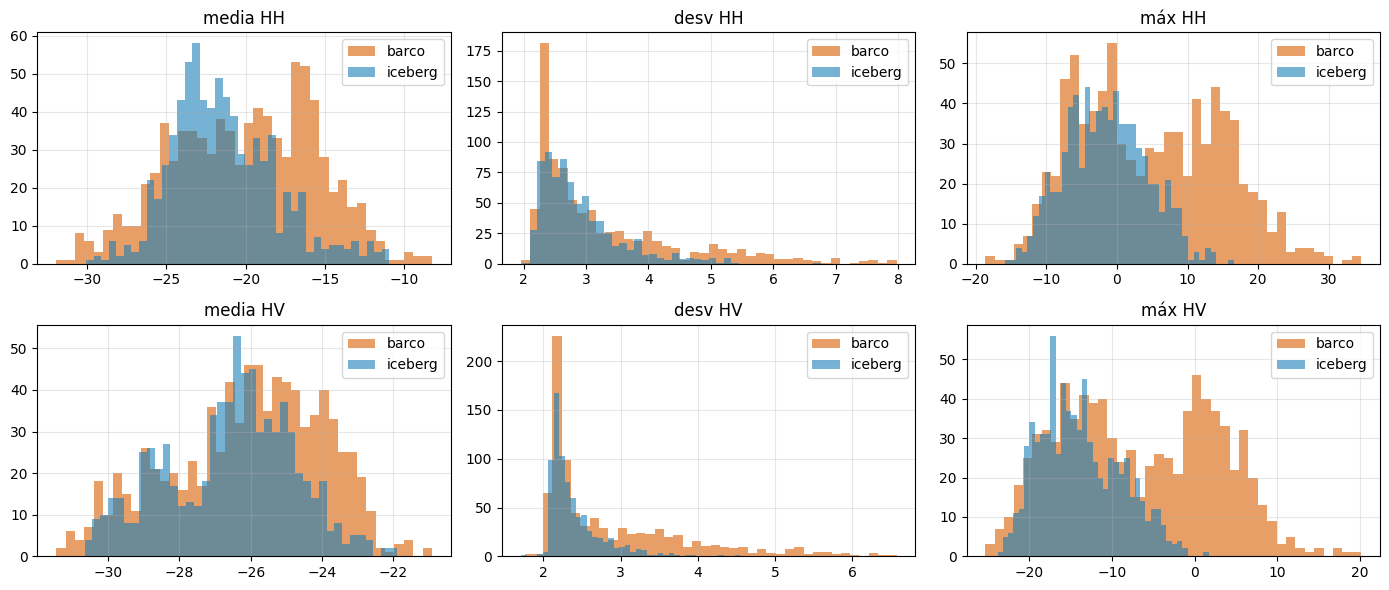

,AUC de un solo descriptor
máx HV,0.721
máx HH,0.672
desv HV,0.627
media HH,0.602
media HV,0.578
desv HH,0.550


In [6]:
def resumen(df, banda):
    a = np.stack([np.asarray(v, dtype=np.float32) for v in df[banda]])
    return a.mean(1), a.std(1), a.max(1)

est = pd.DataFrame({"is_iceberg": df["is_iceberg"]})
for banda, nombre in (("band_1", "HH"), ("band_2", "HV")):
    est[f"media {nombre}"], est[f"desv {nombre}"], est[f"máx {nombre}"] = resumen(df, banda)

fig, ejes = plt.subplots(2, 3, figsize=(14, 6))
for ax, col in zip(ejes.ravel(), [c for c in est.columns if c != "is_iceberg"]):
    for c in (0, 1):
        ax.hist(est.loc[est["is_iceberg"] == c, col], bins=40, alpha=0.6, color=COLORES[c], label=ETIQUETAS[c])
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

# AUC de usar cada descriptor solo; se toma max(AUC, 1-AUC) porque el sentido de la relación no importa
auc_desc = {c: max(roc_auc_score(est["is_iceberg"], est[c]), 1 - roc_auc_score(est["is_iceberg"], est[c]))
            for c in est.columns if c != "is_iceberg"}
auc_desc = pd.Series(auc_desc).rename("AUC de un solo descriptor")
auc_desc.sort_values(ascending=False).round(3).to_frame()

## El ángulo de incidencia

`inc_angle` describe la geometría de la toma, no el objeto. Si aun así se relacionara con la etiqueta, un modelo podría aprender ese atajo en lugar de las propiedades del objeto. Se revisan tres cosas:

1. Qué fracción de las imágenes no tiene ángulo y de qué clase son.
2. Cuánta información sobre la clase aporta el ángulo por sí solo.
3. Si las imágenes con un mismo valor de ángulo tienden a compartir etiqueta.

is_iceberg      barco  iceberg
ángulo ausente                
False             718      753
True              133        0

Imágenes sin ángulo: 133 (8.3% del total)
De ellas, barcos: 100%


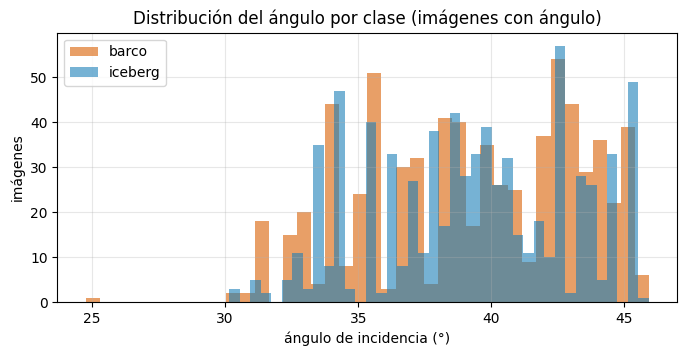

In [7]:
falta = df["inc_angle"].isna()
tabla = pd.crosstab(falta.rename("ángulo ausente"), df["is_iceberg"].map(ETIQUETAS))
print(tabla, end="\n\n")
print(f"Imágenes sin ángulo: {falta.sum()} ({falta.mean():.1%} del total)")
print(f"De ellas, barcos: {(df.loc[falta, 'is_iceberg'] == 0).mean():.0%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
for c in (0, 1):
    ax.hist(df.loc[(df["is_iceberg"] == c) & ~falta, "inc_angle"], bins=40, alpha=0.6,
            color=COLORES[c], label=ETIQUETAS[c])
ax.set_xlabel("ángulo de incidencia (°)"); ax.set_ylabel("imágenes"); ax.legend()
ax.set_title("Distribución del ángulo por clase (imágenes con ángulo)")
plt.show()

In [8]:
y = df["is_iceberg"].values
ang = df["inc_angle"]

auc_valor = roc_auc_score(y, ang.fillna(ang.mean()))                   # valor numérico, ausentes -> media
auc_ausente = roc_auc_score(y, (~falta).astype(int))                   # solo "tiene / no tiene ángulo"
auc_solo_presentes = roc_auc_score(y[~falta], ang[~falta])             # valor, solo imágenes con ángulo

print("AUC de clasificar usando únicamente el ángulo (0.5 = sin información):")
print(f"  valor del ángulo (ausentes -> media)   : {auc_valor:.3f}")
print(f"  indicador 'tiene ángulo / no tiene'    : {auc_ausente:.3f}")
print(f"  valor del ángulo, solo imágenes con él : {auc_solo_presentes:.3f}")

AUC de clasificar usando únicamente el ángulo (0.5 = sin información):
  valor del ángulo (ausentes -> media)   : 0.492
  indicador 'tiene ángulo / no tiene'    : 0.578
  valor del ángulo, solo imágenes con él : 0.494


### Ángulos repetidos

El ángulo es un número continuo con muchos decimales, así que dos imágenes con el mismo valor suelen provenir de la misma pasada del satélite sobre un mismo objeto o zona. Se cuenta cuántos valores se repiten y qué tan puros son esos grupos (todas las imágenes con la misma etiqueta) frente a lo que ocurriría por azar. El azar se estima barajando las etiquetas 500 veces y manteniendo los mismos grupos.

Valores de ángulo distintos: 878 (de 1471 imágenes con ángulo)
Valores repetidos en 2 o más imágenes: 217, que cubren 810 imágenes
Grupos repetidos con una sola etiqueta: 97.2%
Esperado si la etiqueta no dependiera del ángulo: 43.5% ± 2.7%


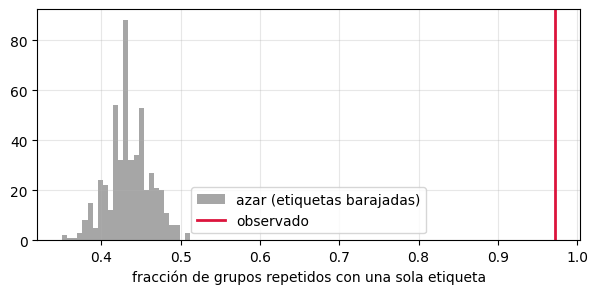

In [9]:
validos = df.loc[~falta, ["inc_angle", "is_iceberg"]].copy()
validos["grupo"] = validos["inc_angle"].round(4)
tam = validos.groupby("grupo").size()
repetidos = tam[tam > 1].index
dup = validos[validos["grupo"].isin(repetidos)]

def fraccion_pura(etiquetas, grupos):
    return (pd.Series(etiquetas).groupby(np.asarray(grupos)).nunique() == 1).mean()

observado = fraccion_pura(dup["is_iceberg"].values, dup["grupo"].values)
rng = np.random.default_rng(0)
azar = np.array([fraccion_pura(rng.permutation(dup["is_iceberg"].values), dup["grupo"].values)
                 for _ in range(500)])

print(f"Valores de ángulo distintos: {validos['grupo'].nunique()} (de {len(validos)} imágenes con ángulo)")
print(f"Valores repetidos en 2 o más imágenes: {len(repetidos)}, que cubren {len(dup)} imágenes")
print(f"Grupos repetidos con una sola etiqueta: {observado:.1%}")
print(f"Esperado si la etiqueta no dependiera del ángulo: {azar.mean():.1%} ± {azar.std():.1%}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(azar, bins=25, color="grey", alpha=0.7, label="azar (etiquetas barajadas)")
ax.axvline(observado, color="crimson", lw=2, label="observado")
ax.set_xlabel("fracción de grupos repetidos con una sola etiqueta"); ax.legend()
plt.show()

## Resumen de hallazgos

In [10]:
n_falta = int(falta.sum())
pct_barcos = (df.loc[falta, "is_iceberg"] == 0).mean()
z = (observado - azar.mean()) / (azar.std() + 1e-12)

print(f"1. Hay {len(df)} imágenes etiquetadas: {int(conteo.get(0, 0))} barcos y {int(conteo.get(1, 0))} icebergs "
      f"({conteo.min() / len(df):.0%} de la clase minoritaria): el balance es razonable y la exactitud es una métrica válida.")
print(f"2. {n_falta} imágenes no tienen ángulo y el {pct_barcos:.0%} de ellas son barcos. "
      f"El simple hecho de que falte el ángulo alcanza un AUC de {auc_ausente:.2f}.")
print(f"3. El valor del ángulo, entre las imágenes que lo tienen, aporta un AUC de {auc_solo_presentes:.2f}.")
print(f"4. Los ángulos repetidos comparten etiqueta en {observado:.0%} de los casos frente a {azar.mean():.0%} "
      f"esperado por azar ({z:.1f} desviaciones). ", end="")
print("Esto indica que una partición aleatoria puede poner imágenes casi idénticas en train y validación."
      if observado > azar.mean() + 3 * azar.std() else "No se observa una dependencia clara.")
print(f"5. Los descriptores simples más informativos son '{auc_desc.sort_values(ascending=False).index[0]}' "
      f"(AUC {auc_desc.max():.2f}), lo que deja margen para que una CNN aproveche la forma y la textura.")

1. Hay 1604 imágenes etiquetadas: 851 barcos y 753 icebergs (47% de la clase minoritaria): el balance es razonable y la exactitud es una métrica válida.
2. 133 imágenes no tienen ángulo y el 100% de ellas son barcos. El simple hecho de que falte el ángulo alcanza un AUC de 0.58.
3. El valor del ángulo, entre las imágenes que lo tienen, aporta un AUC de 0.49.
4. Los ángulos repetidos comparten etiqueta en 97% de los casos frente a 43% esperado por azar (19.6 desviaciones). Esto indica que una partición aleatoria puede poner imágenes casi idénticas en train y validación.
5. Los descriptores simples más informativos son 'máx HV' (AUC 0.72), lo que deja margen para que una CNN aproveche la forma y la textura.


### Consecuencias para el modelado

- Las particiones de entrenamiento y validación deben **agruparse por ángulo** para no medir memorización de pasadas del satélite.
- Si se usa el ángulo como entrada, conviene comprobar qué parte del rendimiento procede de él.
- Que falte el ángulo es una señal que no existiría en un caso de uso real con la misma distribución; debe tratarse conscientemente.